In [1]:
# import libraries
!pip install "flaml[automl]"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.preprocessing import normalize, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)
from flaml import AutoML
from scipy import stats
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 349.7/349.7 kB 21.7 MB/s eta 0:00:00
  Attempting uninstall: xgboost
    Found existing installation: xgboost 3.2.0
    Uninstalling xgboost-3.2.0:
      Successfully uninstalled xgboost-3.2.0


In [2]:
# data loading and cleaning
df = pd.read_csv('qsar_data.csv')
df = df.dropna() #drop missing values
def clean_column(name): # replace anything that's not a letter, number, or underscore
    return re.sub(r'[^A-Za-z0-9_]', '_', name)
df.columns = [clean_column(col) for col in df.columns]
df

,SpMax_L,J_Dz_e_,nHM,F01_N_N_,F04_C_N_,NssssC,nCb_,C_,nCp,nO,...,C_026,F02_C_N_,nHDon,SpMax_B_m_,Psi_i_A,nN,SM6_B_m_,nArCOOR,nX,Class
0,3.919,2.6909,0,0,0,0,0,31.4,2,0,...,0,0,0,2.949,1.591,0,7.253,0,0,1
1,4.170,2.1144,0,0,0,0,0,30.8,1,1,...,0,0,0,3.315,1.967,0,7.257,0,0,1
2,3.932,3.2512,0,0,0,0,0,26.7,2,4,...,0,0,1,3.076,2.417,0,7.601,0,0,1
3,3.000,2.7098,0,0,0,0,0,20.0,0,2,...,0,0,1,3.046,5.000,0,6.690,0,0,1
4,4.236,3.3944,0,0,0,0,0,29.4,2,4,...,0,0,0,3.351,2.405,0,8.003,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
832,3.000,1.7389,1,0,0,0,0,25.0,2,0,...,0,0,0,6.867,2.083,0,11.561,0,1,0
833,5.051,3.5320,0,0,2,0,0,30.0,2,6,...,0,2,6,3.519,2.435,1,8.710,0,0,0
834,4.876,2.8477,0,0,2,0,0,30.0,2,2,...,0,3,2,3.631,2.900,2,8.126,0,0,0
835,4.953,3.4085,0,0,2,0,2,40.0,1,2,...,1,2,0,3.853,2.803,1,8.521,0,0,0


In [3]:
# train/test split
x = df.drop(columns=['Class'])  # Drop the target column.
y = df['Class']  # Keep only the target column.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

In [4]:
# Set up Auto ML model
model_aml = AutoML(seed=42,
               time_budget=30,
               metric="roc_auc",
               task="classification",
               n_splits=5
               )

In [5]:
# Normalize input data
scaler = MinMaxScaler() # Setup the scaling tool
x_train_scaled = scaler.fit_transform(x_train) # Fit the scaler on the training data
x_test_scaled = scaler.transform(x_test) # Transform the testing data using the fitted scaler

In [6]:
# Set up DL model
x_train_scaled.shape # 585 rows, 41 columns (features)

tf.keras.utils.set_random_seed(42) # This is to use the fixed initial parameters in the DL model

model_dl = Sequential()
model_dl.add(Input(shape=(41,)))
model_dl.add(Dense(100,activation='relu'))
model_dl.add(Dense(70,activation='relu'))
model_dl.add(Dense(8,activation='relu'))
model_dl.add(Dense(1,activation='sigmoid'))

model_dl.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [7]:
# training/testing
model_aml.fit(x_train, y_train) #auto ml
model_dl.fit(x_train_scaled, y_train, epochs=100, validation_split=0.2) #dl

[flaml.automl.logger: 05-13 22:05:00] {2375} INFO - task = classification
[flaml.automl.logger: 05-13 22:05:00] {2386} INFO - Evaluation method: cv
[flaml.automl.logger: 05-13 22:05:00] {2489} INFO - Minimizing error metric: 1-roc_auc
[flaml.automl.logger: 05-13 22:05:00] {2606} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd', 'lrl1']
[flaml.automl.logger: 05-13 22:05:00] {2911} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 05-13 22:05:01] {3046} INFO - Estimated sufficient time budget=6083s. Estimated necessary time budget=141s.
[flaml.automl.logger: 05-13 22:05:01] {3097} INFO -  at 0.7s,	estimator lgbm's best error=1.4713e-01,	best estimator lgbm's best error=1.4713e-01
[flaml.automl.logger: 05-13 22:05:01] {2911} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 05-13 22:05:02] {3097} INFO -  at 1.5s,	estimator lgbm's best error=1.4713e-01,	best estimator lgbm's best error=1.4713e-01
[flaml.auto

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 05-13 22:05:02] {3097} INFO -  at 1.9s,	estimator sgd's best error=2.7544e-01,	best estimator lgbm's best error=1.4713e-01
[flaml.automl.logger: 05-13 22:05:02] {2911} INFO - iteration 3, current learner sgd
[flaml.automl.logger: 05-13 22:05:04] {3097} INFO -  at 3.2s,	estimator sgd's best error=1.2667e-01,	best estimator sgd's best error=1.2667e-01
[flaml.automl.logger: 05-13 22:05:04] {2911} INFO - iteration 4, current learner lgbm
[flaml.automl.logger: 05-13 22:05:04] {3097} INFO -  at 3.5s,	estimator lgbm's best error=1.3514e-01,	best estimator sgd's best error=1.2667e-01
[flaml.automl.logger: 05-13 22:05:04] {2911} INFO - iteration 5, current learner xgboost
[flaml.automl.logger: 05-13 22:05:05] {3097} INFO -  at 4.8s,	estimator xgboost's best error=1.5138e-01,	best estimator sgd's best error=1.2667e-01
[flaml.automl.logger: 05-13 22:05:05] {2911} INFO - iteration 6, current learner extra_tree
[flaml.automl.logger: 05-13 22:05:06] {3097} INFO -  at 5.2s,	esti

In [8]:
# Predictions
# AutoML
y_predict_aml = model_aml.predict(x_test)
y_prob_aml = model_aml.predict_proba(x_test)[:, 1]

# DL
y_prob_dl = model_dl.predict(x_test_scaled).flatten()
y_predict_dl = (y_prob_dl > 0.5).astype(int) # convert to 0/1

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


In [9]:
# Performance analysis - Confusion Matrix
cf_matrix_aml = confusion_matrix(y_test, y_predict_aml)
cf_matrix_dl = confusion_matrix(y_test, y_predict_dl)

print("AutoML Results")
print(cf_matrix_aml)
print(classification_report(y_test, y_predict_aml, digits=4))

print("\nDL Results")
print(cf_matrix_dl)
print(classification_report(y_test, y_predict_dl, digits=4))

AutoML Results
[[153  14]
 [ 21  64]]
              precision    recall  f1-score   support

           0     0.8793    0.9162    0.8974       167
           1     0.8205    0.7529    0.7853        85

    accuracy                         0.8611       252
   macro avg     0.8499    0.8346    0.8413       252
weighted avg     0.8595    0.8611    0.8596       252


DL Results
[[152  15]
 [ 13  72]]
              precision    recall  f1-score   support

           0     0.9212    0.9102    0.9157       167
           1     0.8276    0.8471    0.8372        85

    accuracy                         0.8889       252
   macro avg     0.8744    0.8786    0.8764       252
weighted avg     0.8896    0.8889    0.8892       252



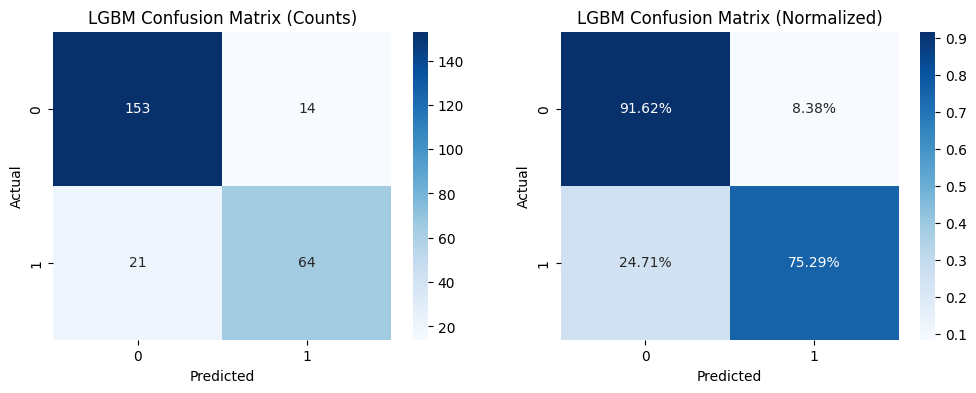

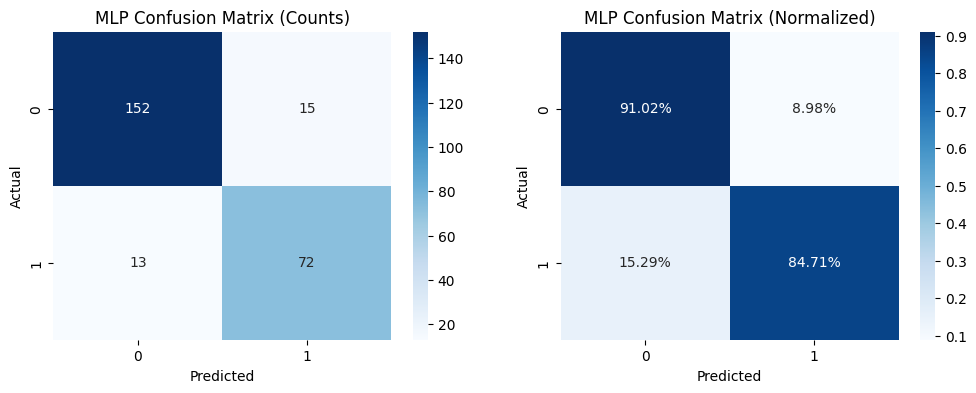

In [10]:
# Visualization - Confusion Matrix
def plot_conf_matrix(cf_matrix, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    sns.heatmap(cf_matrix, annot=True, fmt='g', cmap='Blues', ax=ax1)
    sns.heatmap(
        normalize(cf_matrix, axis=1, norm='l1'),
        annot=True, fmt='.2%',
        cmap='Blues', ax=ax2
    )

    ax1.set_title(f'{title} (Counts)')
    ax2.set_title(f'{title} (Normalized)')

    for ax in [ax1, ax2]:
        ax.set_xlabel('Predicted')
        ax.set_ylabel('Actual')
        ax.set_xticklabels(['0', '1'])
        ax.set_yticklabels(['0', '1'])

    plt.show()

plot_conf_matrix(cf_matrix_aml, "LGBM Confusion Matrix")
plot_conf_matrix(cf_matrix_dl, "MLP Confusion Matrix")

In [11]:
# performance analysis - ROC AUC
auc_aml = roc_auc_score(y_test, y_prob_aml)
auc_dl = roc_auc_score(y_test, y_prob_dl)

print(f"ROC AUC for LGBM: {auc_aml:.4f}")
print(f"ROC AUC for DL: {auc_dl:.4f}")

ROC AUC for LGBM: 0.9195
ROC AUC for DL: 0.9286


<Figure size 600x600 with 0 Axes>

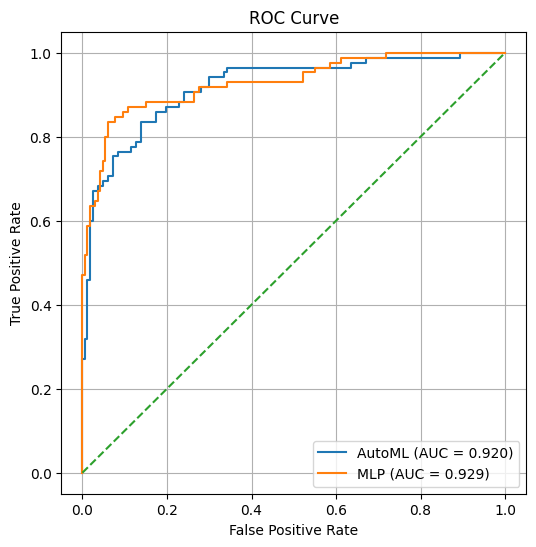

In [12]:
# Visualization - ROC curve
fpr_dl, tpr_dl, _ = roc_curve(y_test, y_prob_dl)
fpr_aml, tpr_aml, _ = roc_curve(y_test, y_prob_aml)
plt.figure(figsize=(6,6))

fpr_aml, tpr_aml, _ = roc_curve(y_test, y_prob_aml)
fpr_dl, tpr_dl, _ = roc_curve(y_test, y_prob_dl)

plt.figure(figsize=(6,6))
plt.plot(fpr_aml, tpr_aml, label=f'AutoML (AUC = {auc_aml:.3f})')
plt.plot(fpr_dl, tpr_dl, label=f'MLP (AUC = {auc_dl:.3f})')
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid()
plt.show()

In [13]:
# hypothesis testing
abs_errors_aml = abs(y_test - y_predict_aml)
abs_errors_dl = abs(y_test - y_predict_dl)
t_statistics, p_value = stats.ttest_rel(abs_errors_aml, abs_errors_dl, alternative='less')
print(f"t-statistic = {t_statistics:.4f}")
print(f"p-value = {p_value:.6f}")

t-statistic = 1.2587
p-value = 0.895345
